In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [36]:
# 读取数据
# 用 sep='\t' 读 TSV；第一行是表头；用 na_values 把空串当作 NaN
df = pd.read_csv(
    "earthquakes-2026-10-14_21-39-07_+0800.tsv",
    sep="\t",
    na_values=["", " "],
    low_memory=False
)

# 去掉完全为空的行（有些行只有 Search Parameters 列有值）
df = df.dropna(subset=["Id"])

print("总行数：", len(df))
print("列名：", df.columns.tolist())

总行数： 6697
列名： ['Search Parameters', 'Id', 'Year', 'Mo', 'Dy', 'Hr', 'Mn', 'Sec', 'Tsu', 'Vol', 'Country', 'Area', 'Region', 'Location Name', 'Latitude', 'Longitude', 'Focal Depth (km)', 'Mag', 'Mw', 'Ms', 'Mb', 'Ml', 'Mfa', 'Unk', 'MMI Int', 'Deaths', 'Death Description', 'Missing', 'Missing Description', 'Injuries', 'Injuries Description', 'Damage ($Mil)', 'Damage Description', 'Houses Destroyed', 'Houses Destroyed Description', 'Houses Damaged', 'Houses Damaged Description', 'Total Deaths', 'Total Death Description', 'Total Missing', 'Total Missing Description', 'Total Injuries', 'Total Injuries Description', 'Total Damage ($Mil)', 'Total Damage Description', 'Total Houses Destroyed', 'Total Houses Destroyed Description', 'Total Houses Damaged', 'Total Houses Damaged Description']


In [43]:
# 统一列名，确保代码用到的列都存在
# 先去掉列名首尾空格，再把常见别名映射到代码使用的标准名
df.columns = df.columns.str.strip()

# 建立 实际列名 -> 代码标准列名 的映射
# 按 print(df.columns.tolist()) 的结果，只保留你实际存在的键即可
rename_map = {
    # 国家列
    "Country Name": "Country",
    "country":      "Country",
    "COUNTRY":      "Country",

    # 震级列（最关键，之前报错就在这里）
    "Magnitude":     "Mag_max",
    "Mag":           "Mag_max",
    "mag":           "Mag_max",
    "EQ Magnitude":  "Mag_max",
    "Magnitude_max": "Mag_max",

    # 其他列（若实际列名不同也一并统一）
    "Location":  "Location Name",
    "Month":     "Mo",
    "Day":       "Dy",
    "month":     "Mo",
    "day":       "Dy",
}

# 只对存在的列改名，不存在的键自动忽略
df = df.rename(columns={k: v for k, v in rename_map.items() if k in df.columns})

# 自检：确保后续代码需要的列都存在
required_cols = ["Country", "Mag_max", "Year", "Mo", "Dy", "Location Name"]
missing = [c for c in required_cols if c not in df.columns]
if missing:
    print("警告：以下列仍不存在，请根据 df.columns.tolist() 补充 rename_map：", missing)
    print("当前所有列名：", df.columns.tolist())
else:
    print("列名检查通过：", required_cols)


# 国家名归一化映射表（保持原样）
COUNTRY_MAP = {
    # ---------- 东亚 ----------
    "CHINA": "CHINA",
    "TAIWAN": "CHINA",
    "HONG KONG": "CHINA",
    "MACAU": "CHINA",

    # ---------- 美国及其属地 ----------
    "USA": "UNITED STATES",
    "USA TERRITORY": "UNITED STATES",
    "UNITED STATES": "UNITED STATES",

    # ---------- 英国及其海外领地 ----------
    "UK": "UNITED KINGDOM",
    "UNITED KINGDOM": "UNITED KINGDOM",
    "UK TERRITORY": "UNITED KINGDOM",
    "BRITISH VIRGIN ISLANDS": "UNITED KINGDOM",

    # ---------- 法国海外领地 ----------
    "FRANCE": "FRANCE",
    "NEW CALEDONIA": "FRANCE",
    "FRENCH POLYNESIA": "FRANCE",
    "WALLIS AND FUTUNA (FRENCH TERRITORY)": "FRANCE",
    "GUADELOUPE": "FRANCE",
    "MARTINIQUE": "FRANCE",
    "FRENCH GUIANA": "FRANCE",

    # ---------- 荷兰 ----------
    "NETHERLANDS": "NETHERLANDS",

    # ---------- 俄罗斯 ----------
    "RUSSIA": "RUSSIA",

    # ---------- 前南斯拉夫 / 巴尔干 ----------
    "SERBIA": "SERBIA",
    "MONTENEGRO": "MONTENEGRO",
    "BOSNIA-HERZEGOVINA": "BOSNIA AND HERZEGOVINA",
    "CROATIA": "CROATIA",
    "SLOVENIA": "SLOVENIA",
    "NORTH MACEDONIA": "NORTH MACEDONIA",
    "KOSOVO": "KOSOVO",

    # ---------- 前苏联加盟共和国 ----------
    "ARMENIA": "ARMENIA",
    "AZERBAIJAN": "AZERBAIJAN",
    "GEORGIA": "GEORGIA",
    "KAZAKHSTAN": "KAZAKHSTAN",
    "KYRGYZSTAN": "KYRGYZSTAN",
    "TAJIKISTAN": "TAJIKISTAN",
    "TURKMENISTAN": "TURKMENISTAN",
    "UZBEKISTAN": "UZBEKISTAN",
    "UKRAINE": "UKRAINE",

    # ---------- 中东 / 西亚 ----------
    "TURKEY": "TURKEY",
    "SYRIA": "SYRIA",
    "LEBANON": "LEBANON",
    "ISRAEL": "ISRAEL",
    "JORDAN": "JORDAN",
    "IRAQ": "IRAQ",
    "IRAN": "IRAN",
    "SAUDI ARABIA": "SAUDI ARABIA",
    "YEMEN": "YEMEN",
    "OMAN": "OMAN",
    "CYPRUS": "CYPRUS",

    # ---------- 南亚 / 东南亚 ----------
    "INDIA": "INDIA",
    "PAKISTAN": "PAKISTAN",
    "BANGLADESH": "BANGLADESH",
    "NEPAL": "NEPAL",
    "BHUTAN": "BHUTAN",
    "SRI LANKA": "SRI LANKA",
    "MYANMAR (BURMA)": "MYANMAR",
    "MYANMAR": "MYANMAR",
    "THAILAND": "THAILAND",
    "LAOS": "LAOS",
    "VIETNAM": "VIETNAM",
    "MALAYSIA": "MALAYSIA",
    "INDONESIA": "INDONESIA",
    "PHILIPPINES": "PHILIPPINES",

    # ---------- 大洋洲 ----------
    "AUSTRALIA": "AUSTRALIA",
    "NEW ZEALAND": "NEW ZEALAND",
    "PAPUA NEW GUINEA": "PAPUA NEW GUINEA",
    "FIJI": "FIJI",
    "VANUATU": "VANUATU",
    "SOLOMON ISLANDS": "SOLOMON ISLANDS",
    "TONGA": "TONGA",
    "SAMOA": "SAMOA",
    "KERMADEC ISLANDS (NEW ZEALAND)": "NEW ZEALAND",
    "MICRONESIA, FED. STATES OF": "MICRONESIA",
    "PALAU": "PALAU",
    "KIRIBATI": "KIRIBATI",

    # ---------- 欧洲其他国家 ----------
    "ITALY": "ITALY",
    "GREECE": "GREECE",
    "ALBANIA": "ALBANIA",
    "BULGARIA": "BULGARIA",
    "ROMANIA": "ROMANIA",
    "HUNGARY": "HUNGARY",
    "AUSTRIA": "AUSTRIA",
    "SWITZERLAND": "SWITZERLAND",
    "GERMANY": "GERMANY",
    "BELGIUM": "BELGIUM",
    "SPAIN": "SPAIN",
    "PORTUGAL": "PORTUGAL",
    "ICELAND": "ICELAND",
    "NORWAY": "NORWAY",
    "POLAND": "POLAND",
    "SLOVAKIA": "SLOVAKIA",
    "CZECH REPUBLIC": "CZECHIA",
    "ESTONIA": "ESTONIA",
    "BELARUS": "BELARUS",

    # ---------- 非洲 ----------
    "EGYPT": "EGYPT",
    "LIBYA": "LIBYA",
    "TUNISIA": "TUNISIA",
    "ALGERIA": "ALGERIA",
    "MOROCCO": "MOROCCO",
    "SUDAN": "SUDAN",
    "SOUTH SUDAN": "SOUTH SUDAN",
    "ETHIOPIA": "ETHIOPIA",
    "ERITREA": "ERITREA",
    "DJIBOUTI": "DJIBOUTI",
    "SOMALIA": "SOMALIA",
    "KENYA": "KENYA",
    "TANZANIA": "TANZANIA",
    "UGANDA": "UGANDA",
    "RWANDA": "RWANDA",
    "BURUNDI": "BURUNDI",
    "CONGO": "DEMOCRATIC REPUBLIC OF THE CONGO",
    "GABON": "GABON",
    "CAMEROON": "CAMEROON",
    "NIGERIA": "NIGERIA",
    "GHANA": "GHANA",
    "COTE D'IVOIRE": "CÔTE D'IVOIRE",
    "TOGO": "TOGO",
    "BENIN": "BENIN",
    "GUINEA": "GUINEA",
    "SIERRA LEONE": "SIERRA LEONE",
    "SENEGAL": "SENEGAL",
    "MALI": "MALI",
    "MALAWI": "MALAWI",
    "MOZAMBIQUE": "MOZAMBIQUE",
    "ZAMBIA": "ZAMBIA",
    "ZIMBABWE": "ZIMBABWE",
    "SOUTH AFRICA": "SOUTH AFRICA",
    "MADAGASCAR": "MADAGASCAR",
    "COMOROS": "COMOROS",
    "MAURITIUS": "MAURITIUS",

    # ---------- 美洲 ----------
    "CANADA": "CANADA",
    "MEXICO": "MEXICO",
    "GUATEMALA": "GUATEMALA",
    "BELIZE": "BELIZE",
    "HONDURAS": "HONDURAS",
    "EL SALVADOR": "EL SALVADOR",
    "NICARAGUA": "NICARAGUA",
    "COSTA RICA": "COSTA RICA",
    "PANAMA": "PANAMA",
    "CUBA": "CUBA",
    "JAMAICA": "JAMAICA",
    "HAITI": "HAITI",
    "DOMINICAN REPUBLIC": "DOMINICAN REPUBLIC",
    "PUERTO RICO": "UNITED STATES",
    "TRINIDAD AND TOBAGO": "TRINIDAD AND TOBAGO",
    "BARBADOS": "BARBADOS",
    "SAINT LUCIA": "SAINT LUCIA",
    "SAINT VINCENT AND THE GRENADINES": "SAINT VINCENT AND THE GRENADINES",
    "GRENADA": "GRENADA",
    "ANTIGUA AND BARBUDA": "ANTIGUA AND BARBUDA",
    "DOMINICA": "DOMINICA",
    "COLOMBIA": "COLOMBIA",
    "VENEZUELA": "VENEZUELA",
    "ECUADOR": "ECUADOR",
    "PERU": "PERU",
    "BOLIVIA": "BOLIVIA",
    "CHILE": "CHILE",
    "ARGENTINA": "ARGENTINA",
    "URUGUAY": "URUGUAY",
    "PARAGUAY": "PARAGUAY",
    "BRAZIL": "BRAZIL",

    # ---------- 其他 / 特殊 ----------
    "ANTARCTICA": "ANTARCTICA",
    "ATLANTIC OCEAN": "ATLANTIC OCEAN",
    "INDIAN OCEAN": "INDIAN OCEAN",
    "PACIFIC OCEAN": "PACIFIC OCEAN",
    "BERING SEA": "BERING SEA",
    "SOLOMON SEA": "SOLOMON SEA",
    "TASMAN SEA": "TASMAN SEA",
    "SOUTH GEORGIA AND THE SOUTH SANDWICH ISLANDS": "SOUTH GEORGIA AND THE SOUTH SANDWICH ISLANDS",
    "AZORES (PORTUGAL)": "PORTUGAL",
    "CANARY ISLANDS": "SPAIN",
}


def normalize_country(name):
    """把原始国家名映射到当前国际通用国家名；未收录的保留原样"""
    if pd.isna(name):
        return np.nan
    name = str(name).strip().upper()
    return COUNTRY_MAP.get(name, name)


# 新建归一化后的国家列
df["Country_Norm"] = df["Country"].apply(normalize_country)

列名检查通过： ['Country', 'Mag_max', 'Year', 'Mo', 'Dy', 'Location Name']


In [44]:
# 1.1 
# Total Deaths 转数值
df["Total Deaths"] = pd.to_numeric(df["Total Deaths"], errors="coerce")

# 按归一化国家分组求和
deaths_by_country = (
    df.groupby("Country_Norm")["Total Deaths"]
      .sum(min_count=1)          # min_count=1：全是 NaN 的组返回 NaN，避免误当 0
      .dropna()                  # 去掉完全没死亡数据的国家
      .sort_values(ascending=False)
)

# 打印前 20 
print("=== 总死亡人数前 20 的国家（国家已归一化） ===")
print(deaths_by_country.head(20).to_string())

# 同时打印原始名 → 归一化名的对照，便于核对合并情况 
mapping_check = (
    df[["Country", "Country_Norm"]]
      .dropna()
      .drop_duplicates()
      .sort_values(["Country_Norm", "Country"])
)
print("\n=== 原始名 → 归一化名 对照表 ===")
print(mapping_check.to_string(index=False))

=== 总死亡人数前 20 的国家（国家已归一化） ===
Country_Norm
CHINA           2164250.0
TURKEY          1008867.0
IRAN             761656.0
SYRIA            488326.0
ITALY            417297.0
HAITI            323782.0
JAPAN            319510.0
AZERBAIJAN       319251.0
INDONESIA        283485.0
ARMENIA          175000.0
PAKISTAN         143714.0
ECUADOR          134445.0
TURKMENISTAN     110412.0
PERU              97009.0
PORTUGAL          88923.0
GREECE            83658.0
IRAQ              70200.0
CHILE             70175.0
INDIA             63413.0
ISRAEL            58368.0

=== 原始名 → 归一化名 对照表 ===
                                     Country                                 Country_Norm
                                 AFGHANISTAN                                  AFGHANISTAN
                                     ALBANIA                                      ALBANIA
                                     ALGERIA                                      ALGERIA
                                  ANTARCTICA         

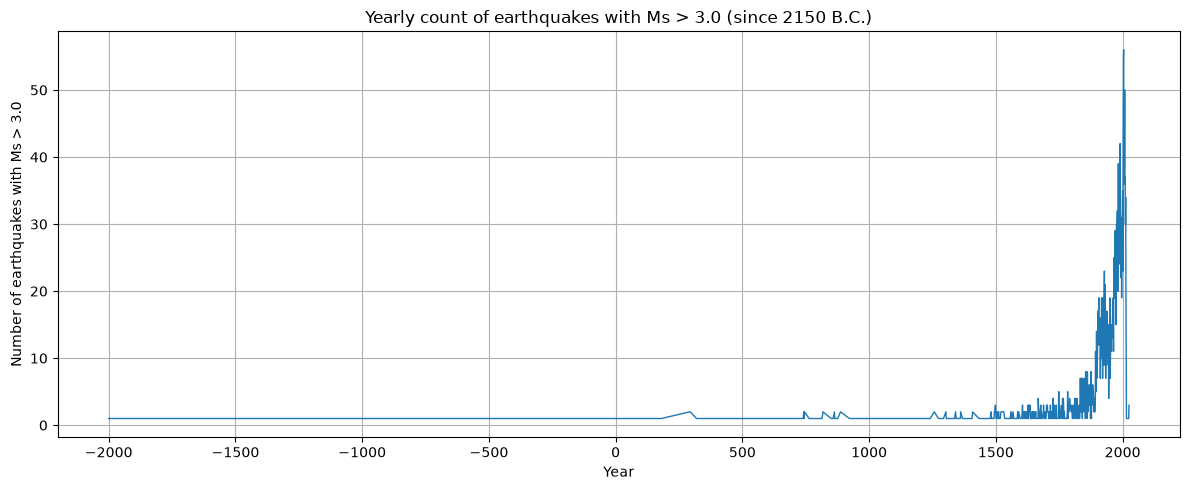

In [38]:
# 1.2
# Ms 列转数值
df["Ms"] = pd.to_numeric(df["Ms"], errors="coerce")

# 过滤 Ms > 3.0 且 Year 有值
mask = (df["Ms"] > 3.0) & (df["Year"].notna())
eq_ms = df.loc[mask, ["Year", "Ms"]].copy()

# Year 转整数
eq_ms["Year"] = eq_ms["Year"].astype(int)

# 按年份统计数量
eq_per_year = eq_ms.groupby("Year").size().sort_index()

# 画图
plt.figure(figsize=(12, 5))
plt.plot(eq_per_year.index, eq_per_year.values, linewidth=1)
plt.xlabel("Year")
plt.ylabel("Number of earthquakes with Ms > 3.0")
plt.title("Yearly count of earthquakes with Ms > 3.0 (since 2150 B.C.)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [45]:



# CountEq_LargestEq（修复：先转数值再 idxmax）

def CountEq_LargestEq(country):
    """
    参数：country —— 归一化后的国家名（如 'CHINA'、'UNITED STATES'）
    返回：
      (a) 该国地震总数
      (b) 该国最大地震的日期和地点（字符串）
    """
    sub = df[df["Country_Norm"] == country].copy()
    total = len(sub)

    if total == 0:
        return 0, None

    # 震级列可能是字符串，先转成数值，避免字典序比较出错
    sub["Mag_max"] = pd.to_numeric(sub["Mag_max"], errors="coerce")

    # 找震级最大的记录；若全为 NaN 则取第一条
    if sub["Mag_max"].notna().any():
        idx = sub["Mag_max"].idxmax()
    else:
        idx = sub.index[0]

    row = sub.loc[idx]

    # 安全整数转换（避免 Year/Mo/Dy 含非数字时报 ValueError）
    def safe_int(v):
        try:
            return int(float(v))
        except (ValueError, TypeError):
            return "?"

    year = safe_int(row["Year"])
    mo   = safe_int(row["Mo"])
    dy   = safe_int(row["Dy"])
    loc  = row["Location Name"] if pd.notna(row["Location Name"]) else "Unknown"
    mag  = row["Mag_max"] if pd.notna(row["Mag_max"]) else "?"

    # 处理公元前年份显示
    if isinstance(year, int) and year < 0:
        year_str = f"{abs(year)} B.C."
    else:
        year_str = str(year)

    return total, f"{year_str}-{mo}-{dy}, {loc}, Mag={mag}"


# 应用到所有国家，按总数降序输出

all_countries = sorted(df["Country_Norm"].dropna().unique())

results = []
for c in all_countries:
    n, info = CountEq_LargestEq(c)
    results.append((c, n, info))

results.sort(key=lambda x: x[1], reverse=True)

print("=== 各国地震总数及最大地震（国家已归一化，按总数降序） ===")
print(f"{'Country':40s} | {'Count':>6s} | Largest earthquake")
print("-" * 120)
for c, n, info in results:
    print(f"{c:40s} | {n:6d} | {info}")

=== 各国地震总数及最大地震（国家已归一化，按总数降序） ===
Country                                  |  Count | Largest earthquake
------------------------------------------------------------------------------------------------------------------------
CHINA                                    |    729 | 1668-7-25, CHINA:  SHANDONG PROVINCE, Mag=8.5
JAPAN                                    |    429 | 2011-3-11, JAPAN:  HONSHU, Mag=9.1
INDONESIA                                |    427 | 2004-12-26, INDONESIA:  SUMATRA:  ACEH:  OFF WEST COAST, Mag=9.1
IRAN                                     |    385 | 856-12-22, IRAN:  DAMGHAN, QUMIS, Mag=7.9
TURKEY                                   |    359 | 1939-12-26, TURKEY:  ERZINCAN, Mag=7.8
ITALY                                    |    338 | 1915-1-13, ITALY:  MARSICA, AVEZZANO, ABRUZZI, Mag=7.5
UNITED STATES                            |    322 | 1964-3-28, ALASKA, Mag=9.2
GREECE                                   |    296 | 365-7-21, GREECE:  CRETE:  KNOSSOS, Mag=8.0
PHILI

In [7]:
# 读取数据
df = pd.read_csv("Baoan_Weather_1998_2022.csv", low_memory=False)

In [8]:
# 解析 DATE 列，构造时间索引
df["DATE"] = pd.to_datetime(df["DATE"], errors="coerce")
df = df.dropna(subset=["DATE"]).copy()

In [19]:
# 解析 TMP，纯字符串
def parse_tmp(val):
    if not isinstance(val, str):
        return np.nan
    s = val.strip()
    if len(s) < 7 or s[0] not in ("+", "-"):
        return np.nan
    num_q = s.split(",")
    if len(num_q) != 2:
        return np.nan
    num, q = num_q[0].strip(), num_q[1].strip()
    if len(num) != 5 or num[0] != s[0] or not num[1:].isdigit() or not q.isdigit():
        return np.nan
    d, q = num[1:], int(q)
    if d == "9999" or q in (2, 4, 9):
        return np.nan
    t = int(d) / 10.0
    return -t if s[0] == "-" else t

df["temp_c"] = df[tmp_col].apply(parse_tmp)
df = df.dropna(subset=["temp_c"]).sort_values("DATE")

In [20]:
# 月均温 -> 序列 s（index=时间, values=月均温）

s = (df.set_index("DATE")["temp_c"]
       .resample("MS")                    # 按自然月重采样（月初对齐）
       .agg(["mean", "count"])
       .query("count >= 24")["mean"])     # 剔除小样本月
s.name = "tas"

In [21]:
# 距平 = 每月温度 − 该月份多年平均  
#    tas_anom = group_data - group_data.mean(dim='time')

month_clim = s.groupby(s.index.month).transform("mean")   # 各月的多年气候态
tas_anom = s - month_clim                                 # 月度距平序列


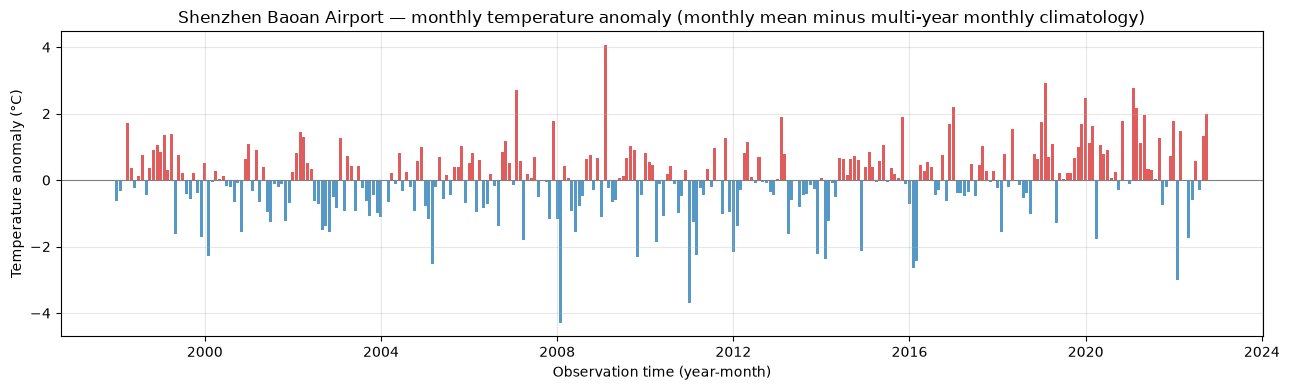

In [28]:
# 逐月距平

fig, ax = plt.subplots(figsize=(13, 4))
colors = ["tab:red" if v > 0 else "tab:blue" for v in tas_anom.values]
ax.bar(tas_anom.index, tas_anom.values, width=25,
       color=colors, alpha=0.75)
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("Observation time (year-month)")
ax.set_ylabel("Temperature anomaly (°C)")
ax.set_title("Shenzhen Baoan Airport — monthly temperature anomaly "
             "(monthly mean minus multi-year monthly climatology)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("tas_monthly_anomaly.png", dpi=150)
plt.show()

In [50]:
df = pd.read_csv('ibtracs.ALL.list.v04r00.csv',
                 usecols=range(17),
                 skiprows=[1, 2], 
                 parse_dates=['ISO_TIME'],
                 na_values=['NOT_NAMED', 'NAME'])

# 数值列统一转换为 float
num_cols = ['SEASON', 'NUMBER', 'LAT', 'LON', 'WMO_WIND', 'WMO_PRES',
            'DIST2LAND', 'LANDFALL']

for col in num_cols:
    if col in df.columns:
        # errors='coerce' 把无法解析的值（含空白、' '）转为 NaN
        df[col] = pd.to_numeric(df[col], errors='coerce')

# -字符串列去掉首尾空白，空串转 NaN
str_cols = ['SID', 'BASIN', 'SUBBASIN', 'NAME', 'NATURE', 'WMO_AGENCY', 'TRACK_TYPE', 'IFLAG']
for col in str_cols:
    if col in df.columns:
        df[col] = df[col].astype('string').str.strip()
        df[col] = df[col].replace('', pd.NA)

df.head()

C:\Users\87727\AppData\Local\Temp\ipykernel_7584\2264799921.py:1: DtypeWarning: Columns (0: NAME) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('ibtracs.ALL.list.v04r00.csv',


,SID,SEASON,NUMBER,BASIN,SUBBASIN,NAME,ISO_TIME,NATURE,LAT,LON,WMO_WIND,WMO_PRES,WMO_AGENCY,TRACK_TYPE,DIST2LAND,LANDFALL,IFLAG
0,1842298N11080,1842,1,NI,BB,<NA>,1842-10-25 06:00:00,NR,10.8709,79.8265,NaN,NaN,<NA>,main,0,0.0,__________P___
1,1842298N11080,1842,1,NI,BB,<NA>,1842-10-25 09:00:00,NR,10.8431,79.3524,NaN,NaN,<NA>,main,0,0.0,__________P___
2,1842298N11080,1842,1,NI,BB,<NA>,1842-10-25 12:00:00,NR,10.8188,78.8772,NaN,NaN,<NA>,main,0,0.0,__________P___
3,1842298N11080,1842,1,NI,BB,<NA>,1842-10-25 15:00:00,NR,10.8000,78.4000,NaN,NaN,<NA>,main,0,0.0,__________O___
4,1842298N11080,1842,1,NI,AS,<NA>,1842-10-25 18:00:00,NR,10.7884,77.9194,NaN,NaN,<NA>,main,0,0.0,__________P___


In [57]:
# 3.1 按 SID 分组，报告风速最大的 10 个飓风的名称
# 每个风暴（SID）有多条记录，先对每个 SID 取 WMO_WIND 最大值，
# 再在“每个风暴的最大风速”中取前 10 名。
storm_max_wind = (df.groupby('SID')
                    .agg({'NAME': 'first',        # 每个 SID 取第一个名字作为风暴名
                          'WMO_WIND': 'max'})     # 每个 SID 的最大风速
                    .dropna(subset=['WMO_WIND'])) # 去掉没有风速记录的风暴

top10 = storm_max_wind.nlargest(10, 'WMO_WIND')
print("=== 3.1 风速最大的 10 个飓风 ===")
print(top10[['NAME', 'WMO_WIND']])

=== 3.1 风速最大的 10 个飓风 ===
                   NAME  WMO_WIND
SID                              
2015293N13266  PATRICIA     185.0
1980214N11330     ALLEN     165.0
1935241N23291      <NA>     160.0
1988253N12306   GILBERT     160.0
1997253N12255     LINDA     160.0
2005289N18282     WILMA     160.0
2019236N10314    DORIAN     160.0
1998295N12284     MITCH     155.0
2005261N21290      RITA     155.0
2009288N07267      RICK     155.0


In [58]:
# 3.2 列出风速最大的20个
# 直接在 3.1 的 per-storm 最大风速表上取前 20 个风速值
top20_wind = storm_max_wind.nlargest(20, 'WMO_WIND')
print("=== 3.2 最强 20 个飓风的风速 ===")
print(top20_wind['WMO_WIND'].tolist())

=== 3.2 最强 20 个飓风的风速 ===
[185.0, 165.0, 160.0, 160.0, 160.0, 160.0, 160.0, 155.0, 155.0, 155.0, 155.0, 150.0, 150.0, 150.0, 150.0, 150.0, 150.0, 150.0, 150.0, 150.0]


In [59]:
# 3.3 按 Basin 统计所有数据点数量
# value_counts() 统计每个 BASIN 出现的行数（即数据点数量）

basin_counts = df['BASIN'].value_counts()
print("=== 3.3 各 Basin 数据点数量 ===")
print(basin_counts)

=== 3.3 各 Basin 数据点数量 ===
BASIN
WP    236576
SI    160668
SP     67119
EP     62412
NI     55401
SA       119
Name: count, dtype: int64[pyarrow]


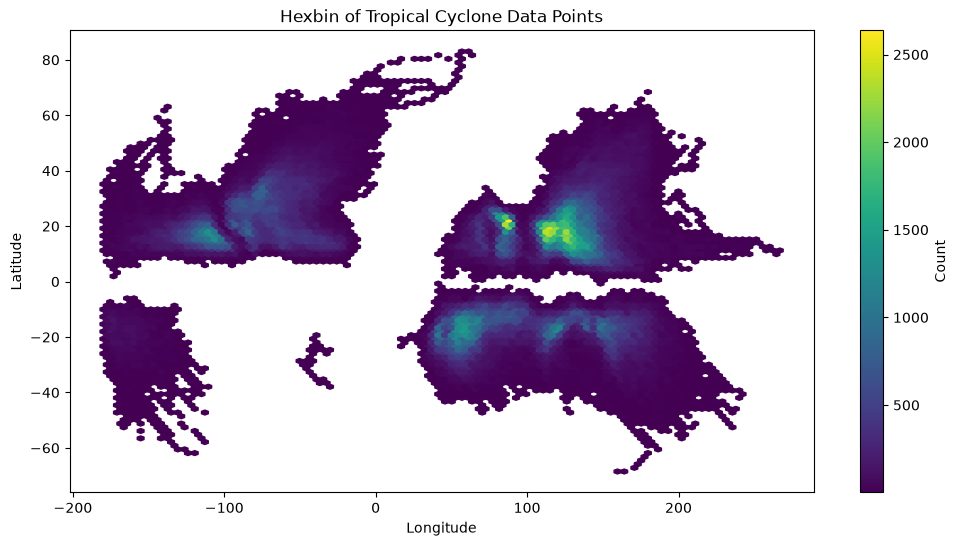

In [60]:
#3.4 经纬度位置的 hexbin 图

# hexbin 用六边形网格聚合散点，适合展示大量点的空间密度
plt.figure(figsize=(12, 6))
plt.hexbin(df['LON'], df['LAT'],
           gridsize=100,      # 网格密度
           cmap='viridis',    # 颜色映射
           mincnt=1)          # 至少 1 个点才着色
plt.colorbar(label='Count')   # 颜色条表示点数
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Hexbin of Tropical Cyclone Data Points')
plt.show()

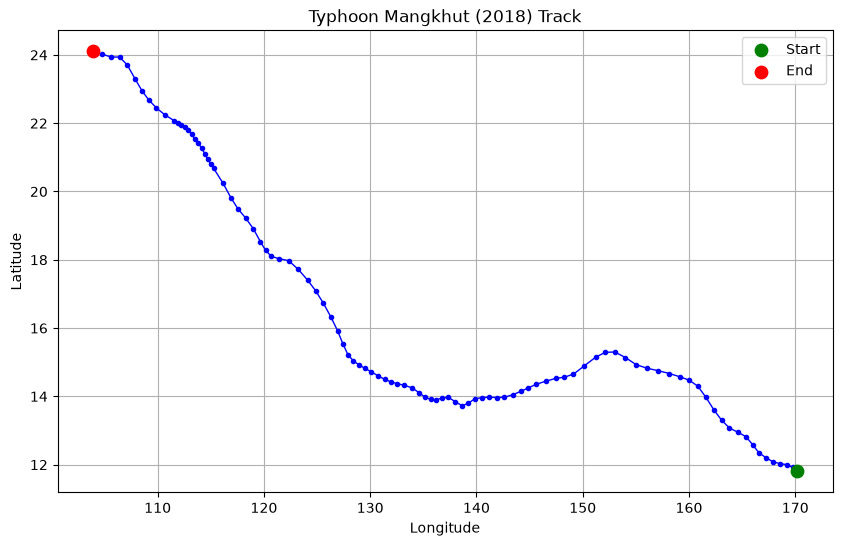

In [61]:
# 3.5 找到 2018 年 Typhoon Mangkhut 并绘制其路径
# 同时用 NAME 和 SEASON 筛选，避免同名风暴跨年混淆

mangkhut = df[(df['NAME'] == 'MANGKHUT') & (df['SEASON'] == 2018)]

plt.figure(figsize=(10, 6))
# 用折线连接路径点，-o 表示带圆点标记
plt.plot(mangkhut['LON'], mangkhut['LAT'], 'b-o', markersize=3, linewidth=1)
# 起点绿色、终点红色，便于识别路径方向
plt.scatter(mangkhut['LON'].iloc[0], mangkhut['LAT'].iloc[0],
            color='green', s=80, label='Start', zorder=5)
plt.scatter(mangkhut['LON'].iloc[-1], mangkhut['LAT'].iloc[-1],
            color='red', s=80, label='End', zorder=5)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Typhoon Mangkhut (2018) Track')
plt.legend()
plt.grid(True)
plt.show()

In [62]:
# 3.6 筛选 1970 年后 WP 和 EP 流域的数据

filtered_df = df[(df['SEASON'] >= 1970) &
                 (df['BASIN'].isin(['WP', 'EP']))].copy()
print(f"=== 3.6 过滤后行数: {len(filtered_df)} ===")

=== 3.6 过滤后行数: 176352 ===


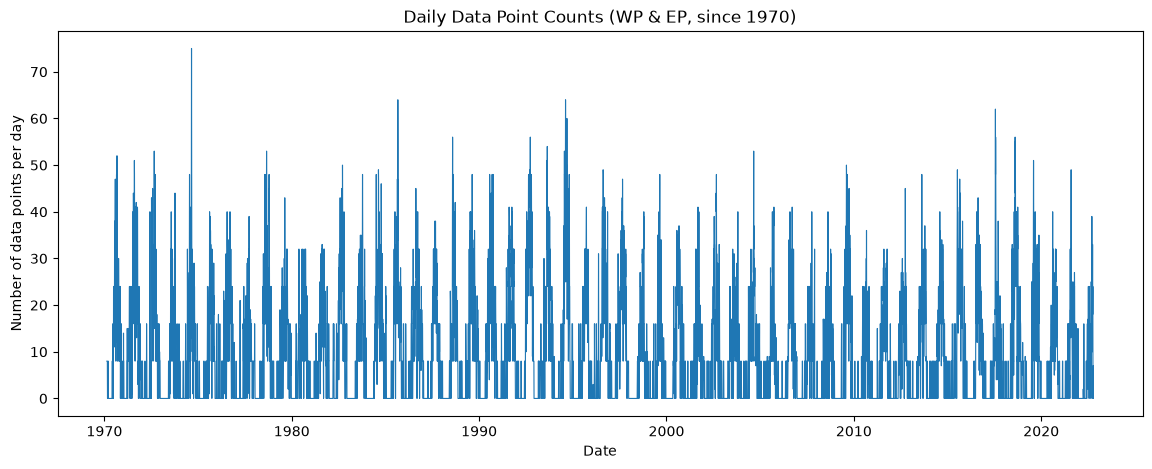

In [63]:
# 3.7 每日数据点数量图
# 基于3.6过滤的行数，把 ISO_TIME 设为索引，按天 resample('D')，size() 得到每天的数据点数
daily_counts = filtered_df.set_index('ISO_TIME').resample('D').size()

plt.figure(figsize=(14, 5))
plt.plot(daily_counts.index, daily_counts.values, linewidth=0.8)
plt.xlabel('Date')
plt.ylabel('Number of data points per day')
plt.title('Daily Data Point Counts (WP & EP, since 1970)')
plt.show()

In [64]:
# 3.8 按一年中的第几天（day of year）计算气候态
# 先把 daily_counts 转回 DataFrame，并计算 day of year
daily_counts_df = daily_counts.reset_index()
daily_counts_df.columns = ['ISO_TIME', 'count']
daily_counts_df['doy'] = daily_counts_df['ISO_TIME'].dt.dayofyear  # 1=1月1日

# 对每个 doy 求多年平均值，即为该日的气候态（climatology）
climatology = daily_counts_df.groupby('doy')['count'].mean()
print("=== 3.8 气候态（前 5 天） ===")
print(climatology.head())

=== 3.8 气候态（前 5 天） ===
doy
1    1.596154
2    1.384615
3    1.423077
4    1.788462
5    2.019231
Name: count, dtype: float64


In [65]:
# 3.9 计算日计数相对气候态的异常
# 用 map 把每个日期的气候态值映射回来，再与当日计数相减得到异常
daily_counts_df['clim'] = daily_counts_df['doy'].map(climatology)
daily_counts_df['anomaly'] = daily_counts_df['count'] - daily_counts_df['clim']

# 以时间为索引保存异常序列
anomaly_series = daily_counts_df.set_index('ISO_TIME')['anomaly']
print("=== 3.9 异常序列（前 5 行） ===")
print(anomaly_series.head())

=== 3.9 异常序列（前 5 行） ===
ISO_TIME
1970-02-19    7.018868
1970-02-20    7.094340
1970-02-21    7.188679
1970-02-22    7.377358
1970-02-23    7.490566
Name: anomaly, dtype: float64


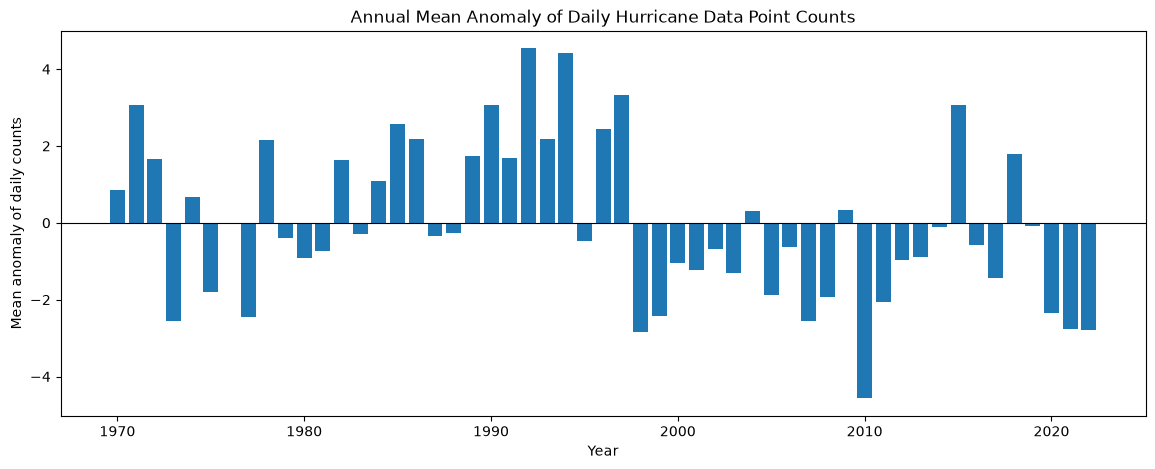

=== 3.10 正异常最大的 5 年 ===
ISO_TIME
1992-12-31    4.537501
1994-12-31    4.415686
1997-12-31    3.330754
1990-12-31    3.073220
2015-12-31    3.067741
Name: anomaly, dtype: float64
=== 3.10 负异常最大的 5 年 ===
ISO_TIME
2010-12-31   -4.570616
1998-12-31   -2.830890
2022-12-31   -2.793204
2021-12-31   -2.751437
2007-12-31   -2.562396
Name: anomaly, dtype: float64


In [67]:
# 3.10 按年重采样异常序列并绘图
# 把逐日异常重采样为年度（'YE' = year end），取年均值
annual_anomaly = anomaly_series.resample('YE').mean()

plt.figure(figsize=(14, 5))
plt.bar(annual_anomaly.index.year, annual_anomaly.values, width=0.8)
plt.axhline(0, color='black', linewidth=0.8)  # 零线参考
plt.xlabel('Year')
plt.ylabel('Mean anomaly of daily counts')
plt.title('Annual Mean Anomaly of Daily Hurricane Data Point Counts')
plt.show()

# 输出异常最显著的正/负年份，用于回答“哪些年份飓风活动异常”
print("=== 3.10 正异常最大的 5 年 ===")
print(annual_anomaly.nlargest(5))
print("=== 3.10 负异常最大的 5 年 ===")
print(annual_anomaly.nsmallest(5))

In [79]:
# 加载 NCEI LCD CSV 文件

df = pd.read_csv('NCEI_1.csv', dtype=str)

In [80]:
# 查看列名和前几行，确认结构
print(df_raw.columns.tolist()[:20])
print(df_raw.head())

['STATION', 'DATE', 'LATITUDE', 'LONGITUDE', 'ELEVATION', 'NAME', 'DP01', 'DP01_ATTRIBUTES', 'DP10', 'DP10_ATTRIBUTES', 'DP1X', 'DP1X_ATTRIBUTES', 'DSND', 'DSND_ATTRIBUTES', 'DSNW', 'DSNW_ATTRIBUTES', 'EMSD', 'EMSD_ATTRIBUTES', 'EMSN', 'EMSN_ATTRIBUTES']
       STATION  DATE  LATITUDE  LONGITUDE  ELEVATION               NAME  DP01  \
0  US10adam004  2006   40.4798   -98.4026      570.0  AYR 3.5 NE, NE US    84   
1  US10adam004  2007   40.4798   -98.4026      570.0  AYR 3.5 NE, NE US    81   
2  US10adam004  2008   40.4798   -98.4026      570.0  AYR 3.5 NE, NE US    91   
3  US10adam004  2009   40.4798   -98.4026      570.0  AYR 3.5 NE, NE US    94   
4  US10adam004  2010   40.4798   -98.4026      570.0  AYR 3.5 NE, NE US    89   

  DP01_ATTRIBUTES  DP10 DP10_ATTRIBUTES  ...   EMSD EMSD_ATTRIBUTES   EMSN  \
0               N    46               N  ...  102.0       ,N,0320,   165.0   
1               N    55               N  ...    NaN             NaN  152.0   
2               N    60 

In [81]:
# 清洗时间列：DATE 是年份字符串，转成整数
df['DATE'] = pd.to_numeric(df['DATE'], errors='coerce')   # 无法解析的变 NaN
df = df.dropna(subset=['DATE']).copy()
df['DATE'] = df['DATE'].astype(int)

# 清洗数值列：去掉首尾空格后转数值，坏值变 NaN
# 直接 astype(float) 会失败，必须先 strip 再 to_numeric(errors='coerce')
num_cols = ['DP01', 'DP10', 'DP1X', 'DSND', 'DSNW', 'EMSD', 'EMSN',
            'EMXP', 'PRCP', 'SNOW']

for col in num_cols:
    # strip 掉首尾空白，空串会变成 NaN
    df[col] = df[col].str.strip()
    # errors='coerce'：无法解析的值（空串、特殊符号）转为 NaN
    df[col] = pd.to_numeric(df[col], errors='coerce')

# 单位换算：EMXP 和 PRCP 原始单位是 0.01 inch，转换为 inch
# （SNOW 在 GHCN-D 中通常是 0.1 inch，这里保持原值或按需转换；
#   为简洁起见，我们只对 PRCP 和 EMXP 除以 100 转成 inch）
df['PRCP_inch'] = df['PRCP'] / 100.0
df['EMXP_inch'] = df['EMXP'] / 100.0

# 处理质量标记（_ATTRIBUTES）
# GHCN-D 中属性列形如 " ,N,0320, "，其中 N = 通过质检。
# 若属性列中没有 'N' 或为空，该数据点可能质量存疑，置为 NaN。
# 这里我们检查 PRCP_ATTRIBUTES，去掉不含 'N' 的记录（保守做法）
prcp_attr = df['PRCP_ATTRIBUTES'].fillna('')
bad_quality_mask = ~prcp_attr.str.contains('N')
print(f"PRCP 质量存疑的记录数: {bad_quality_mask.sum()}")
df.loc[bad_quality_mask, 'PRCP_inch'] = np.nan

# 按年份排序，设为索引 
df = df.sort_values('DATE').set_index('DATE')

# 输出清洗结果
print("=" * 60)
print("4.1 清洗结果")
print("=" * 60)
print(f"有效年份数: {len(df)}")
print(f"年份范围: {df.index.min()} – {df.index.max()}")
print("\n各数值列缺失值数量:")
print(df[num_cols + ['PRCP_inch', 'EMXP_inch']].isnull().sum())
print("\n清洗后前几行（关键列）:")
print(df[['PRCP_inch', 'EMXP_inch', 'DP01', 'DP10']].head())

PRCP 质量存疑的记录数: 0
4.1 清洗结果
有效年份数: 14
年份范围: 2006 – 2021

各数值列缺失值数量:
DP01          0
DP10          0
DP1X          0
DSND         13
DSNW          5
EMSD         13
EMSN          5
EMXP          0
PRCP          0
SNOW          5
PRCP_inch     0
EMXP_inch     0
dtype: int64

清洗后前几行（关键列）:
      PRCP_inch  EMXP_inch  DP01  DP10
DATE                                  
2006      6.486      0.495    84    46
2007      8.026      0.508    81    55
2008      8.677      0.627    91    60
2009      5.425      0.660    94    45
2010      8.056      0.790    89    56


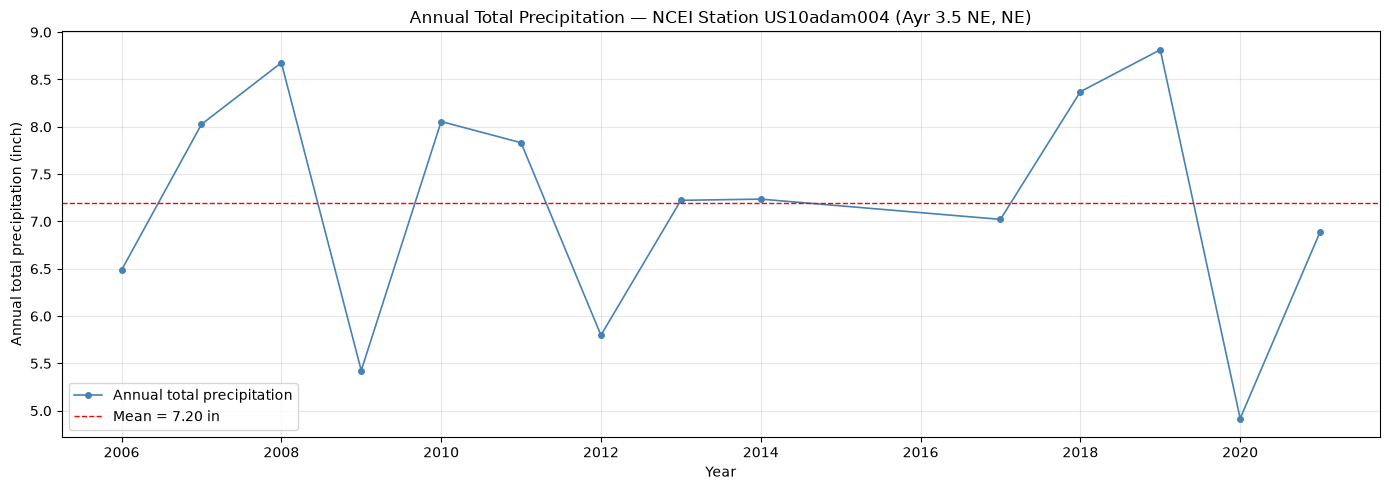

In [84]:
# 4.2 绘制年总降水量时间序列

prcp = df['PRCP_inch'].dropna()   # 去掉缺失年份，保证画图连续

plt.figure(figsize=(14, 5))
# 折线 + 圆点，便于看清每一年的值
plt.plot(prcp.index, prcp.values, 'o-', color='steelblue',
         linewidth=1.2, markersize=4, label='Annual total precipitation')
# 叠加一条水平虚线表示多年平均，便于目视判断偏高/偏低年份
plt.axhline(prcp.mean(), color='red', linestyle='--',
            linewidth=1, label=f'Mean = {prcp.mean():.2f} in')
plt.xlabel('Year')
plt.ylabel('Annual total precipitation (inch)')
plt.title('Annual Total Precipitation — NCEI Station US10adam004 (Ayr 3.5 NE, NE)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [86]:
# 4.3 对年总降水量 PRCP_inch 做统计检查
print("=" * 60)
print("4.3 统计检查结果（变量：年总降水量 PRCP_inch）")
print("=" * 60)

# 检查 1：描述性统计
print("\n[检查 1] 描述性统计:")
print(prcp.describe())
# 报告：均值、标准差、最小/最大值、四分位数

# 检查 2：分布形状（偏度 & 峰度）
skew = prcp.skew()
kurt = prcp.kurtosis()
print("\n[检查 2] 分布形状:")
print(f"  偏度 (Skewness): {skew:.3f}")
print(f"  峰度 (Kurtosis): {kurt:.3f}")
# 偏度 > 0 右偏（极端多雨年拉高尾部）；< 0 左偏
# 峰度 > 0 比正态分布更尖、尾部更厚

# 检查 3：趋势检验
# 用最小二乘拟合年份 vs 降水量，看是否有长期趋势
x = prcp.index.values.astype(float)
y = prcp.values
slope, intercept = np.polyfit(x, y, 1)
# 计算相关系数，衡量线性关系强弱
r = np.corrcoef(x, y)[0, 1]
print("\n[检查 3] 线性趋势:")
print(f"  斜率: {slope:.4f} inch/year")
print(f"  相关系数 r: {r:.3f}")
# 斜率符号表示增多/减少趋势；|r| 越大线性关系越强

# 检查 4：极端值检测（IQR 规则）
Q1, Q3 = prcp.quantile(0.25), prcp.quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
outliers = prcp[(prcp < lower) | (prcp > upper)]
print("\n[检查 4] 异常值检测 (IQR 规则):")
print(f"  Q1={Q1:.2f}, Q3={Q3:.2f}, IQR={IQR:.2f}")
print(f"  正常区间: [{lower:.2f}, {upper:.2f}] inch")
print(f"  异常年份数: {len(outliers)}")
if len(outliers) > 0:
    print(f"  异常年份及值:\n{outliers}")

# 检查 5：自相关（滞后 1、2、3 年）
print("\n[检查 5] 自相关:")
for lag in [1, 2, 3]:
    ac = prcp.autocorr(lag=lag)
    print(f"  滞后 {lag} 年: {ac:.3f}")
# 年际降水通常自相关较弱（接近 0），若显著非零说明存在年际持续性

# 检查 6：与 DP01 的一致性 
# DP01 = 降水≥0.01 inch 的天数，应与年总量正相关
sub = df[['PRCP_inch', 'DP01']].dropna()
corr = sub['PRCP_inch'].corr(sub['DP01'])
print("\n[检查6] PRCP 与 DP01(降水天数) 的相关系数:")
print(f"  r = {corr:.3f}")
# 预期强正相关：雨日越多，年总量通常越大

# 检查 7：滑动平均看年代际变化
# 用 5 年滑动平均平滑年际波动，观察长期趋势
rolling = prcp.rolling(window=5, center=True).mean()
print("\n[检查7] 5 年滑动平均（首尾各 2 年为空，正常）:")
print(rolling.dropna().round(2))

4.3 统计检查结果（变量：年总降水量 PRCP_inch）

[检查 1] 描述性统计:
count    14.000000
mean      7.198071
std       1.206901
min       4.918000
25%       6.586750
50%       7.229500
75%       8.048500
max       8.814000
Name: PRCP_inch, dtype: float64

[检查 2] 分布形状:
  偏度 (Skewness): -0.513
  峰度 (Kurtosis): -0.629

[检查 3] 线性趋势:
  斜率: -0.0190 inch/year
  相关系数 r: -0.079

[检查 4] 异常值检测 (IQR 规则):
  Q1=6.59, Q3=8.05, IQR=1.46
  正常区间: [4.39, 10.24] inch
  异常年份数: 0

[检查 5] 自相关:
  滞后 1 年: -0.279
  滞后 2 年: -0.460
  滞后 3 年: 0.460

[检查6] PRCP 与 DP01(降水天数) 的相关系数:
  r = 0.483

[检查7] 5 年滑动平均（首尾各 2 年为空，正常）:
DATE
2008    7.33
2009    7.60
2010    7.16
2011    6.87
2012    7.23
2013    7.02
2014    7.13
2017    7.73
2018    7.27
2019    7.20
Name: PRCP_inch, dtype: float64
